In [34]:
import pandas as pd
import matplotlib.pyplot as plt

podatki = pd.read_csv("results/metric_dimensions.csv")

#Izberemo samo uspešno rešene primere
podatki = podatki[(podatki["status"] == "optimal") 
                  & (podatki["certificate_ok"])]

print(podatki.head(15))


                    timestamp   n  d  dimension          resolving_set  \
0   2026-11-01T01:03:18+00:00   9  4        4.0           [0, 1, 2, 4]   
1   2026-11-01T01:03:18+00:00  10  4        4.0           [0, 3, 5, 8]   
2   2026-11-01T01:03:18+00:00  11  4        5.0        [0, 2, 3, 6, 8]   
3   2026-11-01T01:03:18+00:00  11  5        5.0        [0, 1, 3, 6, 9]   
4   2026-11-01T01:03:18+00:00  12  4        5.0        [0, 2, 7, 8, 9]   
5   2026-11-01T01:03:18+00:00  12  5        4.0           [0, 3, 6, 9]   
6   2026-11-01T01:03:18+00:00  13  4        6.0    [0, 1, 4, 6, 9, 11]   
7   2026-11-01T01:03:18+00:00  13  5        6.0   [0, 1, 4, 7, 10, 11]   
8   2026-11-01T01:03:18+00:00  13  6        6.0   [0, 7, 8, 9, 10, 11]   
9   2026-11-01T01:03:18+00:00  14  4        6.0     [0, 1, 2, 5, 7, 9]   
10  2026-11-01T01:03:18+00:00  14  5        6.0   [0, 3, 6, 9, 10, 12]   
11  2026-11-01T01:03:18+00:00  14  6        6.0    [0, 1, 2, 4, 7, 11]   
12  2026-11-01T01:03:18+00:00  15  4  

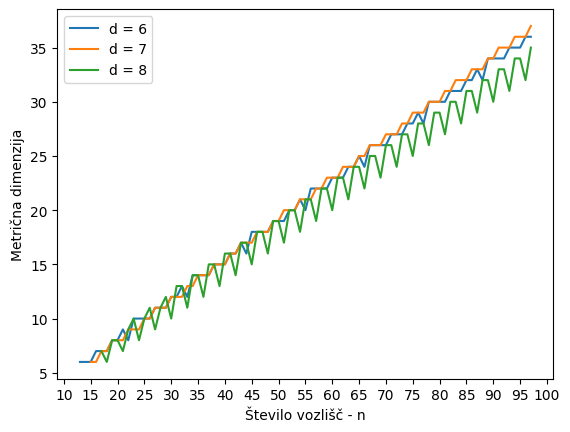

In [35]:
#Narišemo graf za d = 6, 7 in 8
for d in [6, 7, 8]:
    izbrani = podatki[podatki["d"] == d]
    izbrani.sort_values("n")
    plt.plot(izbrani["n"], izbrani["dimension"], label = f"d = {d}")

plt.xlabel("Število vozlišč - n")
plt.ylabel("Metrična dimenzija")
plt.xticks(range(10, 105, 5))
plt.legend()
plt.show()


Iz grafa lahko opazimo, da metrična dimenzija za vse tri vrednosti d v splošnem narašča z večanjem števila vozlišč, vendar ne enakomerno.

Za d = 6 lahko opazimo manjša nihanja in ponavljajočo obliko grafa. 
Pri d = 7 ima graf stopničasto obliko. Lahko opazimo, da je za velike n metrična dimenzija pri d = 7 višja od ostalih dveh vrednostih parametra.
Pri d = 8 pa lahko opazimo cikcakast vzorec, ki se približno od n = 30 ponavlja, medtem ko so pri manjših vrednosti nihanja malo drugačna. Prav tako je metrična dimenzija ponavadi manjša kot pri d = 6 in d = 7. 
Opazimo tudi, da imajo lahko grafi z različnimi vrednostimo d pri istem število vozlišč enako metrično dimenzijo.

Analizirajmo najprej d = 6 in poskusimo ugotoviti matematično formulo za izračun metrične dimenzije.

In [36]:
d6 = podatki[podatki["d"] == 6]
print(d6[["n", "dimension"]].to_string(index=False))

 n  dimension
13        6.0
14        6.0
15        6.0
16        7.0
17        7.0
18        7.0
19        8.0
20        8.0
21        9.0
22        8.0
23       10.0
24       10.0
25       10.0
26       10.0
27       11.0
28       11.0
29       11.0
30       12.0
31       12.0
32       13.0
33       12.0
34       14.0
35       14.0
36       14.0
37       14.0
38       15.0
39       15.0
40       15.0
41       16.0
42       16.0
43       17.0
44       16.0
45       18.0
46       18.0
47       18.0
48       18.0
49       19.0
50       19.0
51       19.0
52       20.0
53       20.0
54       21.0
55       20.0
56       22.0
57       22.0
58       22.0
59       22.0
60       23.0
61       23.0
62       23.0
63       24.0
64       24.0
65       25.0
66       24.0
67       26.0
68       26.0
69       26.0
70       26.0
71       27.0
72       27.0
73       27.0
74       28.0
75       28.0
76       29.0
77       28.0
78       30.0
79       30.0
80       30.0
81       30.0
82       31.0
83    

Iz podatkov lahko opazimo ponavljajoč vzorec metričnih dimenzij. Od n=23 se najprej štirikrat pojavi ena vrednost, nato trikrat vrednost, povečana za 1, dvakrat vrednost, povečana za 1, nato enkrat vrednost, povečana za 1 ter nazadnje enkrat vrednost, zmanjšana za 1. 

Ugotovimo, da se takšen vzorec ponovi na vsakih 11 korakov in da se metrična dimenzija poveča za 4. Zato postavimo domnevo o rekurzivni formuli:

m(n + 11) = m(n) + 4

Preverimo to domnevo na podatkih.

In [66]:
for n in d6["n"]:
    if n + 11 in d6["n"].values:
        prva = d6[d6["n"] == n]["dimension"].values[0]
        druga = d6[d6["n"] == n + 11]["dimension"].values[0]

        if druga != prva + 4:
            print("Domneva ne velja za n =", n)

print("Preverjanje končano.")

Preverjanje končano.


Naša domneva za rekurzivno zvezo torej velja. Zato lahko vsako število vozlišč n razdelimo na večkratnik 11 in ostanek:

n = 11k + r,

kjer je k celoštevilski količnik in r ostanek pri deljenju z 11.
Torej če je naša domneva pravilna, se dimenzija ob povečanju k za 1, poveča za 4. Zato poskusimo s formulo oblike:

m(n) = 4k + c, 

kjer je c konstanta, ki je odvisna od ostanka r.

Poglejmo si najprej podatke za n >= 23.



In [67]:

d6 = d6[d6["n"]>= 23]

d6["k"] = d6["n"] // 11
d6["r"] = d6["n"] % 11

d6["c"] = d6["dimension"] - 4* d6["k"]

print(d6[["n", "dimension", "k", "r", "c"]].head(30))

Empty DataFrame
Columns: [n, dimension, k, r, c]
Index: []


Opazimo, da je c = {2, 2, 2, 2, 3, 3, 3, 4, 5, 0} v enim koraku. Iz podatkov lahko definiramo našo končno domnevo za matematično formulo:

m(n) = 4(n//11) + c,

kjer je c enak 2, če je r = {1, 2, 3, 4}, 3, če je r = {5, 6, 7}, 4, če r = {8, 9}, 5, če je r=10 in 0, če r=0.

In [68]:
c = [0, 2, 2, 2, 2, 3, 3, 3, 4, 4, 5]

d6 = podatki[(podatki["d"] == 6) & (podatki["n"] >= 23)]

for n in d6["n"]:
    k = n // 11
    r = n % 11

    napoved = 4 * k + c[r]
    prava = d6[d6["n"] == n]["dimension"].values[0]   #vzamemo prvo vrednost

    if napoved != prava:
        print("Formula ne velja za n =", n)

print("Preverjanje končano.")

Preverjanje končano.


Ugotovimo, da naša matematična formula deluje za n večji ali enak 23. Preverimo sedaj še za n manjše od 23.

In [69]:
d6 = podatki[(podatki["d"] == 6) & (podatki["n"] < 23)]

for n in d6["n"]:
    k = n // 11
    r = n % 11

    napoved = 4 * k  + c[r]
    prava = d6[d6["n"] == n]["dimension"].values[0]

    if napoved != prava:
        print("Formula ne velja za n =", n)

print("Preverjanje končano.")

Preverjanje končano.


Formula deluje tudi za n < 23, kar pomeni, da je naša matematična formula za izračun metrične dimenzija za d = 6 pravilna.

Sedaj analizirajmo metrične dimenzije za d = 7.

In [70]:
d7 = podatki[podatki["d"] == 7]
print(d7[["n", "dimension"]].to_string(index=False))

 n  dimension
15        6.0
16        6.0
17        7.0
18        7.0
19        8.0
20        8.0
21        8.0
22        9.0
23        9.0
24        9.0
25       10.0
26       10.0
27       11.0
28       11.0
29       11.0
30       12.0
31       12.0
32       12.0
33       13.0
34       13.0
35       14.0
36       14.0
37       14.0
38       15.0
39       15.0
40       15.0
41       16.0
42       16.0
43       17.0
44       17.0
45       17.0
46       18.0
47       18.0
48       18.0
49       19.0
50       19.0
51       20.0
52       20.0
53       20.0
54       21.0
55       21.0
56       21.0
57       22.0
58       22.0
59       23.0
60       23.0
61       23.0
62       24.0
63       24.0
64       24.0
65       25.0
66       25.0
67       26.0
68       26.0
69       26.0
70       27.0
71       27.0
72       27.0
73       28.0
74       28.0
75       29.0
76       29.0
77       29.0
78       30.0
79       30.0
80       30.0
81       31.0
82       31.0
83       32.0
84       32.0
85    

Opazimo lahko ponavljajoč vzorec metričnih dimenzij. Od n = 17 se dvakrat ponovi ista vrednost, potem trikrat vrednost, povečana za 1 ter na zadnje trikrat vrednost, povečana za ena. Ta vzorec se ponovi na vsakih 8 korakov, pri tem se metrična dimenzija poveča za 3. Zapišemo lahko rekurzivno formulo: 

m(n + 8) = m(n) + 3

Najprej preverimo našo domnevo na podatkih.

In [71]:
for n in d7["n"]:
    if n + 8 in d7["n"].values:
        prva = d7[d7["n"] == n]["dimension"].values[0]
        druga = d7[d7["n"] == n + 8]["dimension"].values[0]

        if druga != prva + 3:
            print("Domneva ne velja za n =", n)

print("Preverjanje končano.")

Preverjanje končano.


Naša domneva glede rekurzivne zveze torej velja. Ker je d + 1 = 8, poskusimo poiskati matematično formulo glede na ostanek pri deljenju z 8. Vsako število n lahko zapišemo kot 

n = 8k + r,

kjer je k celoštevilski koeficient in r ostanek pri deljenju. Poskusimo s formulo:

m(n) = 3k + c, 

kjer je c konstanta, ki je odvisna od ostanka c.

In [72]:
d7 = d7[d7["n"]>= 17]

d7["k"] = d7["n"] // 8
d7["r"] = d7["n"] % 8

d7["c"] = d7["dimension"] - 3* d7["k"]

print(d7[["n", "dimension", "k", "r", "c"]].head(30))

      n  dimension  k  r    c
23   17        7.0  2  1  1.0
28   18        7.0  2  2  1.0
33   19        8.0  2  3  2.0
39   20        8.0  2  4  2.0
45   21        8.0  2  5  2.0
52   22        9.0  2  6  3.0
59   23        9.0  2  7  3.0
67   24        9.0  3  0  0.0
75   25       10.0  3  1  1.0
84   26       10.0  3  2  1.0
93   27       11.0  3  3  2.0
103  28       11.0  3  4  2.0
113  29       11.0  3  5  2.0
124  30       12.0  3  6  3.0
135  31       12.0  3  7  3.0
147  32       12.0  4  0  0.0
159  33       13.0  4  1  1.0
171  34       13.0  4  2  1.0
183  35       14.0  4  3  2.0
195  36       14.0  4  4  2.0
207  37       14.0  4  5  2.0
219  38       15.0  4  6  3.0
231  39       15.0  4  7  3.0
243  40       15.0  5  0  0.0
255  41       16.0  5  1  1.0
267  42       16.0  5  2  1.0
279  43       17.0  5  3  2.0
291  44       17.0  5  4  2.0
303  45       17.0  5  5  2.0
315  46       18.0  5  6  3.0


Iz podatkov lahko definiramo našo končno matematično formulo za izračun metrične dimenzije pri d = 7. Zapišemo jo kot:

m(n) = 3(3//8) + c,

kjer je c enak 1, če r = {1, 2}, 2, če r = {3, 4, 5}, 3, če r = {6, 7} in 0 če je r enak 0. 

In [73]:
c = [0, 1, 1, 2, 2, 2, 3, 3]

d7 = podatki[podatki["d"] == 7]

for n in d7["n"]:
    k = n // 8
    r = n % 8

    napoved = 3 * k + c[r]
    prava = d7[d7["n"] == n]["dimension"].values[0]

    if napoved != prava:
        print("Formula ne velja za n =", n)

print("Preverjanje končano.")

Preverjanje končano.


Naša formula za d = 7 je pravilna.